# **Modèles Génératifs avec PyTorch**

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.14.1+cpu
Device : cpu


In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

100.0%
100.0%
100.0%
100.0%

Train : 60000
Test  : 10000


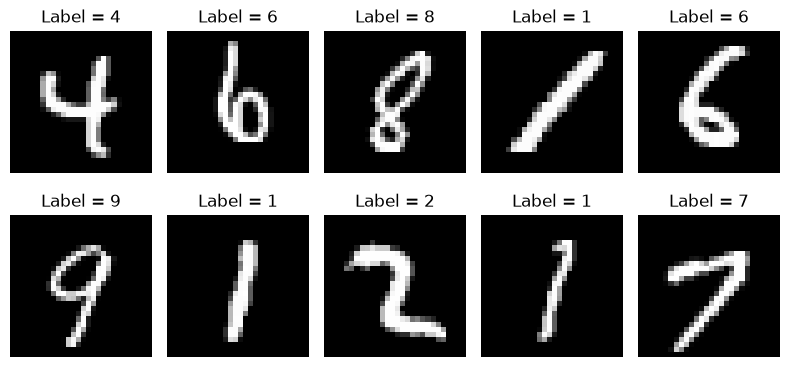

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [6]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4206
Epoch 2/3 - Loss = 0.2007
Epoch 3/3 - Loss = 0.1459


In [7]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.35%


In [9]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

c:\Users\admin\Desktop\TP2\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy = 96.35%


In [10]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [11]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0656
Epoch 2/5 - Loss = 0.0525
Epoch 3/5 - Loss = 0.0497
Epoch 4/5 - Loss = 0.0480
Epoch 5/5 - Loss = 0.0466


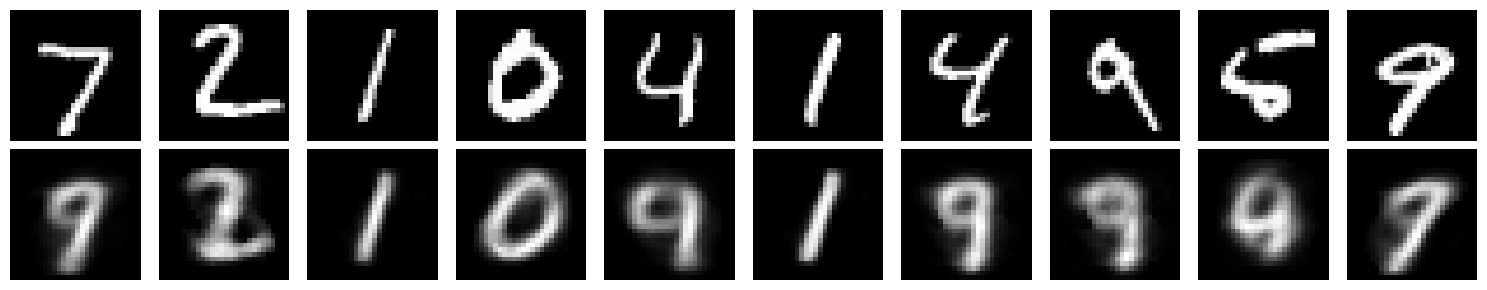

In [12]:
ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show()

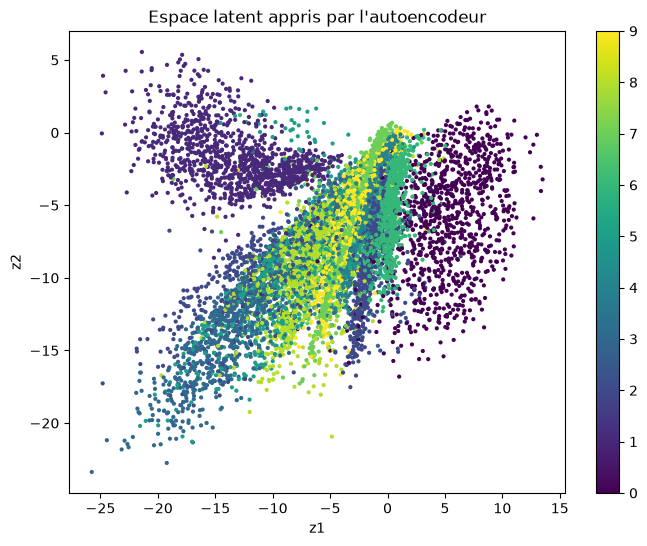

In [13]:
## Visualisation de l'espace latent
ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

In [14]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        # Sélection des images du chiffre demandé
        images = images[labels == chiffre]

        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

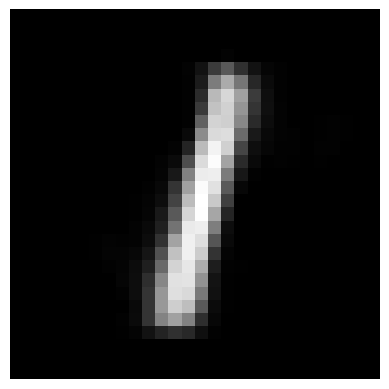

In [15]:
# model : ton autoencodeur entraîné
# train_loader : ton DataLoader MNIST
image = generer_chiffre(ae, train_loader, chiffre=1)

plt.imshow(image[0, 0].numpy(), cmap="gray")
plt.axis("off")
plt.show()

In [16]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [17]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [18]:
## Entrainement
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        total_rec = 0
        total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(
                x_hat,
                x,
                mu,
                logvar,
                beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | "
            f"KL={total_kl/n:.2f}"
        )

train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=193.97 | Rec=189.98 | KL=3.99
Epoch 2/20 | Loss=166.18 | Rec=161.26 | KL=4.93
Epoch 3/20 | Loss=161.27 | Rec=156.08 | KL=5.19
Epoch 4/20 | Loss=157.72 | Rec=152.30 | KL=5.42
Epoch 5/20 | Loss=154.97 | Rec=149.36 | KL=5.61
Epoch 6/20 | Loss=152.90 | Rec=147.14 | KL=5.75
Epoch 7/20 | Loss=151.35 | Rec=145.48 | KL=5.87
Epoch 8/20 | Loss=149.99 | Rec=144.04 | KL=5.96
Epoch 9/20 | Loss=148.99 | Rec=142.96 | KL=6.03
Epoch 10/20 | Loss=148.03 | Rec=141.95 | KL=6.08
Epoch 11/20 | Loss=147.34 | Rec=141.22 | KL=6.12
Epoch 12/20 | Loss=146.53 | Rec=140.36 | KL=6.17
Epoch 13/20 | Loss=145.96 | Rec=139.74 | KL=6.22
Epoch 14/20 | Loss=145.45 | Rec=139.19 | KL=6.26
Epoch 15/20 | Loss=144.96 | Rec=138.65 | KL=6.31
Epoch 16/20 | Loss=144.43 | Rec=138.12 | KL=6.32
Epoch 17/20 | Loss=144.19 | Rec=137.86 | KL=6.33
Epoch 18/20 | Loss=143.85 | Rec=137.47 | KL=6.37
Epoch 19/20 | Loss=143.62 | Rec=137.24 | KL=6.38
Epoch 20/20 | Loss=143.31 | Rec=136.90 | KL=6.41


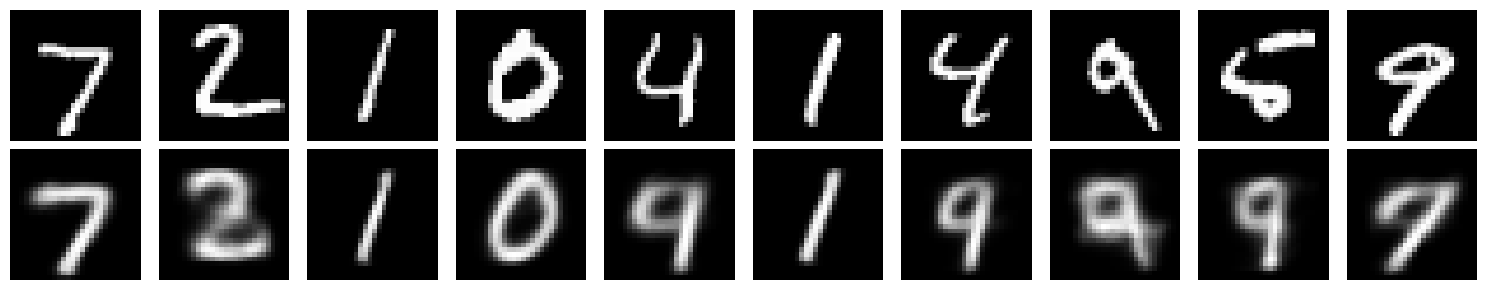

In [19]:
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.tight_layout()
plt.show()

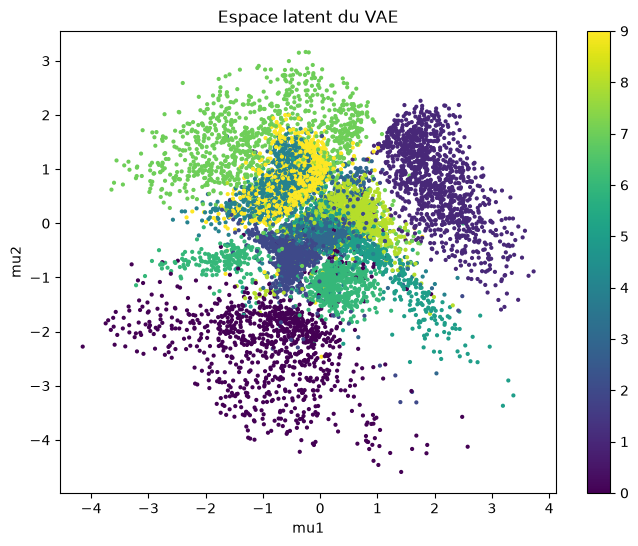

In [20]:
vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=4
)

plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()

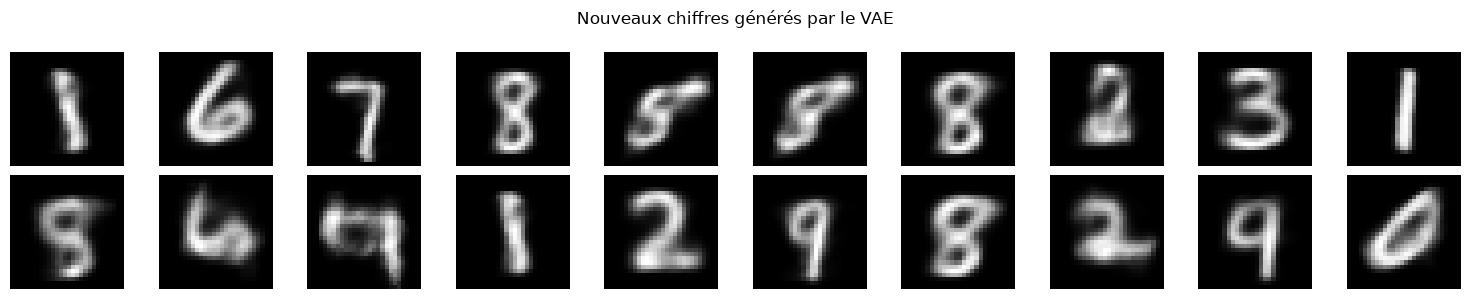

In [21]:
# Générer de nouvelles images
vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()

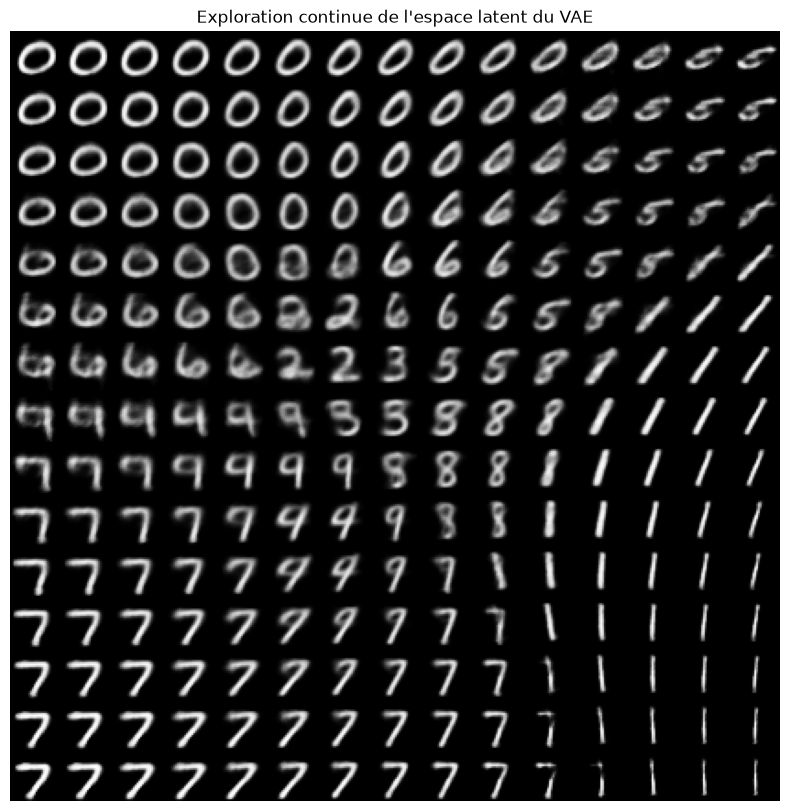

In [22]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            z = torch.tensor(
                [[xi, yi]],
                dtype=torch.float32,
                device=device
            )

            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            figure[
                i*28:(i+1)*28,
                j*28:(j+1)*28
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()

In [23]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

# Facilite la reproductibilité, sans la garantir sur tous les matériels.
torch.manual_seed(42)

# Utiliser le GPU CUDA s'il est disponible.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
image_dim = 28 * 28
batch_size = 128
epochs = 20
learning_rate = 0.0002

output_dir = Path("images_generees")
output_dir.mkdir(exist_ok=True)

print(f"Appareil utilisé : {device}")

Appareil utilisé : cpu


In [24]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
)

In [25]:
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, image_dim),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.network(noise)


generator = Generator(latent_dim).to(device)

In [26]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(image_dim, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1),
        )

    def forward(self, images):
        return self.network(images)


discriminator = Discriminator().to(device)

In [27]:
criterion = nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(
    generator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

optimizer_d = torch.optim.Adam(
    discriminator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

In [28]:
# Même bruit à chaque époque pour comparer les résultats.
fixed_noise = torch.randn(64, latent_dim, device=device)

for epoch in range(epochs):
    generator.train()
    discriminator.train()

    total_loss_d = 0.0
    total_loss_g = 0.0

    for real_images, _ in loader:
        # [B, 1, 28, 28] -> [B, 784]
        real_images = real_images.to(device).flatten(start_dim=1)

        # Le dernier lot peut contenir moins de 128 images.
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(
            current_batch_size, 1, device=device
        )
        fake_labels = torch.zeros(
            current_batch_size, 1, device=device
        )

        # =====================================
        # A. Entraîner le discriminateur
        # =====================================
        discriminator.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)

        # Évaluer les vraies images.
        real_scores = discriminator(real_images)
        loss_real = criterion(real_scores, real_labels)

        # Créer de fausses images à partir de bruit.
        noise = torch.randn(
            current_batch_size, latent_dim, device=device
        )
        fake_images = generator(noise)

        # Couper le gradient vers G pendant cette étape.
        fake_scores = discriminator(fake_images.detach())
        loss_fake = criterion(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2

        loss_d.backward()
        optimizer_d.step()

        # =====================================
        # B. Entraîner le générateur
        # =====================================
        discriminator.requires_grad_(False)
        optimizer_g.zero_grad(set_to_none=True)

        # Nouvelle évaluation avec D qui vient d'être mis à jour.
        fake_scores = discriminator(fake_images)

        # G veut que ses images soient classées "réelles".
        loss_g = criterion(fake_scores, real_labels)

        loss_g.backward()
        optimizer_g.step()

        total_loss_d += loss_d.item()
        total_loss_g += loss_g.item()

    print(
        f"Époque {epoch + 1:02d}/{epochs} | "
        f"Loss D : {total_loss_d / len(loader):.4f} | "
        f"Loss G : {total_loss_g / len(loader):.4f}"
    )

    # =====================================
    # C. Sauvegarder des exemples
    # =====================================
    generator.eval()

    with torch.no_grad():
        samples = generator(fixed_noise)
        samples = samples.view(-1, 1, 28, 28)

        # [-1, 1] -> [0, 1] pour enregistrer les images.
        samples = (samples + 1) / 2

        save_image(
            samples,
            output_dir / f"epoch_{epoch + 1:03d}.png",
            nrow=8,
        )

# Sauvegarder les paramètres appris.
torch.save(generator.state_dict(), "generator_mnist.pt")

Époque 01/20 | Loss D : 0.4405 | Loss G : 1.4161
Époque 02/20 | Loss D : 0.3543 | Loss G : 2.1691
Époque 03/20 | Loss D : 0.3247 | Loss G : 2.4462
Époque 04/20 | Loss D : 0.3207 | Loss G : 2.4961
Époque 05/20 | Loss D : 0.3099 | Loss G : 2.5721
Époque 06/20 | Loss D : 0.3464 | Loss G : 2.2689
Époque 07/20 | Loss D : 0.2938 | Loss G : 2.5984
Époque 08/20 | Loss D : 0.3044 | Loss G : 2.6211
Époque 09/20 | Loss D : 0.3055 | Loss G : 2.6300
Époque 10/20 | Loss D : 0.3049 | Loss G : 2.6626
Époque 11/20 | Loss D : 0.2857 | Loss G : 2.6051
Époque 12/20 | Loss D : 0.2914 | Loss G : 2.7132
Époque 13/20 | Loss D : 0.2974 | Loss G : 2.4950
Époque 14/20 | Loss D : 0.3303 | Loss G : 2.2616
Époque 15/20 | Loss D : 0.3625 | Loss G : 2.1018
Époque 16/20 | Loss D : 0.3704 | Loss G : 1.9852
Époque 17/20 | Loss D : 0.4079 | Loss G : 1.7792
Époque 18/20 | Loss D : 0.4183 | Loss G : 1.6946
Époque 19/20 | Loss D : 0.4451 | Loss G : 1.6037
Époque 20/20 | Loss D : 0.4574 | Loss G : 1.5300


In [29]:
# Générer des images
generator.eval()

with torch.no_grad():
    new_noise = torch.randn(16, latent_dim, device=device)

    new_images = generator(new_noise)
    new_images = new_images.view(-1, 1, 28, 28)
    new_images = (new_images + 1) / 2

    save_image(
        new_images,
        output_dir / "nouveaux_chiffres.png",
        nrow=4,
    )

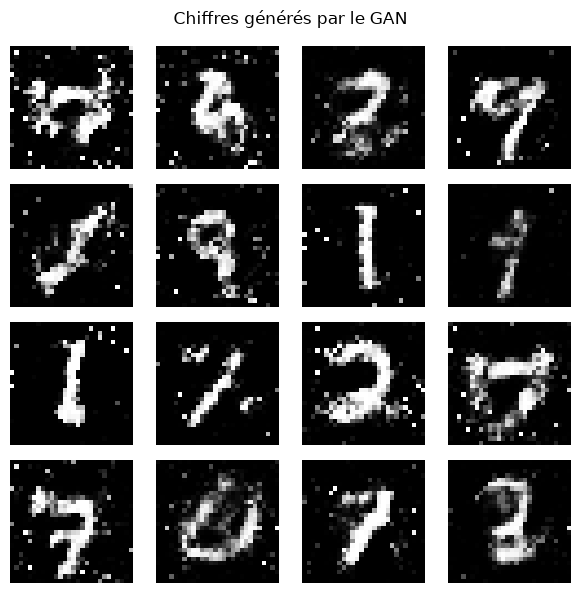

In [30]:
# Générer et visualiser des images
import matplotlib.pyplot as plt
import torch

# Mode évaluation
generator.eval()

# Générer 16 images sans calculer de gradients
with torch.no_grad():
    noise = torch.randn(16, latent_dim, device=device)
    images = generator(noise)

    # [16, 784] -> [16, 1, 28, 28]
    images = images.reshape(-1, 1, 28, 28)

    # Convertir les pixels de [-1, 1] vers [0, 1]
    images = ((images + 1) / 2).clamp(0, 1)

    # Matplotlib utilise les données sur CPU
    images = images.cpu()

# Afficher une grille de 4 × 4
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

fig.suptitle("Chiffres générés par le GAN")
plt.tight_layout()
plt.show()

Époque 01/20 | Loss D : 0.4405 | Loss G : 1.4161
Époque 02/20 | Loss D : 0.3543 | Loss G : 2.1691
Époque 03/20 | Loss D : 0.3247 | Loss G : 2.4462
Époque 04/20 | Loss D : 0.3207 | Loss G : 2.4961
Époque 05/20 | Loss D : 0.3099 | Loss G : 2.5721
Époque 06/20 | Loss D : 0.3464 | Loss G : 2.2689
Époque 07/20 | Loss D : 0.2938 | Loss G : 2.5984
Époque 08/20 | Loss D : 0.3044 | Loss G : 2.6211
Époque 09/20 | Loss D : 0.3055 | Loss G : 2.6300
Époque 10/20 | Loss D : 0.3049 | Loss G : 2.6626
Époque 11/20 | Loss D : 0.2857 | Loss G : 2.6051
Époque 12/20 | Loss D : 0.2914 | Loss G : 2.7132
Époque 13/20 | Loss D : 0.2974 | Loss G : 2.4950
Époque 14/20 | Loss D : 0.3303 | Loss G : 2.2616
Époque 15/20 | Loss D : 0.3625 | Loss G : 2.1018
Époque 16/20 | Loss D : 0.3704 | Loss G : 1.9852
Époque 17/20 | Loss D : 0.4079 | Loss G : 1.7792
Époque 18/20 | Loss D : 0.4183 | Loss G : 1.6946
Époque 19/20 | Loss D : 0.4451 | Loss G : 1.6037
Époque 20/20 | Loss D : 0.4574 | Loss G : 1.5300


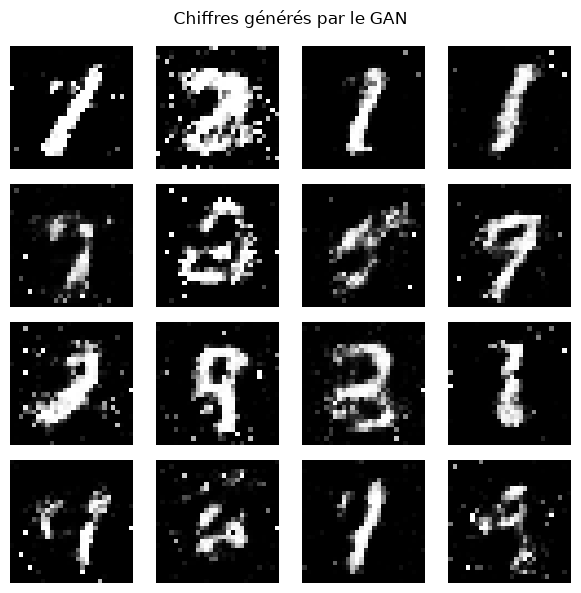

In [31]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

# -------------------------
# Configuration
# -------------------------
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
batch_size = 128
epochs = 20
learning_rate = 2e-4

output_dir = Path("images_generees")
output_dir.mkdir(exist_ok=True)

# -------------------------
# Données : images de 28 × 28
# -------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    # Passage de [0, 1] à [-1, 1], comme la sortie du générateur
    transforms.Normalize((0.5,), (0.5,)),
])

dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
)

# -------------------------
# Générateur : bruit -> image
# -------------------------
generator = nn.Sequential(
    nn.Linear(latent_dim, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 28 * 28),
    nn.Tanh(),  # Pixels dans [-1, 1]
).to(device)

# -------------------------
# Discriminateur : image -> score
# -------------------------
discriminator = nn.Sequential(
    nn.Linear(28 * 28, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 1),
    # Pas de Sigmoid : inclus dans BCEWithLogitsLoss
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(
    generator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

optimizer_d = torch.optim.Adam(
    discriminator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

# Même bruit à chaque époque pour visualiser la progression
fixed_noise = torch.randn(64, latent_dim, device=device)

# -------------------------
# Entraînement
# -------------------------
for epoch in range(epochs):
    total_loss_d = 0.0
    total_loss_g = 0.0

    for real_images, _ in loader:
        real_images = real_images.to(device).view(-1, 28 * 28)
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(current_batch_size, 1, device=device)
        fake_labels = torch.zeros(current_batch_size, 1, device=device)

        # 1. Entraîner le discriminateur
        discriminator.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)

        real_scores = discriminator(real_images)
        loss_real = criterion(real_scores, real_labels)

        noise = torch.randn(current_batch_size, latent_dim, device=device)
        fake_images = generator(noise)

        # detach() empêche de modifier le générateur pendant cette étape
        fake_scores = discriminator(fake_images.detach())
        loss_fake = criterion(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2
        loss_d.backward()
        optimizer_d.step()

        # 2. Entraîner le générateur
        # On fige les paramètres de D, mais on garde le gradient vers G.
        discriminator.requires_grad_(False)
        optimizer_g.zero_grad(set_to_none=True)

        fake_scores = discriminator(fake_images)

        # G cherche à faire classer ses images comme "vraies".
        loss_g = criterion(fake_scores, real_labels)

        loss_g.backward()
        optimizer_g.step()

        total_loss_d += loss_d.item()
        total_loss_g += loss_g.item()

    print(
        f"Époque {epoch + 1:02d}/{epochs} | "
        f"Loss D : {total_loss_d / len(loader):.4f} | "
        f"Loss G : {total_loss_g / len(loader):.4f}"
    )

    # Sauvegarder une grille de 64 images
    generator.eval()
    with torch.no_grad():
        samples = generator(fixed_noise).view(-1, 1, 28, 28)

        # Repasser de [-1, 1] à [0, 1]
        samples = (samples + 1) / 2

        save_image(
            samples,
            output_dir / f"epoch_{epoch + 1:03d}.png",
            nrow=8,
        )
    generator.train()
# Mode évaluation
generator.eval()

# Générer 16 images sans calculer de gradients
with torch.no_grad():
    noise = torch.randn(16, latent_dim, device=device)
    images = generator(noise)

    # [16, 784] -> [16, 1, 28, 28]
    images = images.reshape(-1, 1, 28, 28)

    # Convertir les pixels de [-1, 1] vers [0, 1]
    images = ((images + 1) / 2).clamp(0, 1)

    # Matplotlib utilise les données sur CPU
    images = images.cpu()

# Afficher une grille de 4 × 4
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

fig.suptitle("Chiffres générés par le GAN")
plt.tight_layout()
plt.show()
# Sauvegarder les poids du générateur
torch.save(generator.state_dict(), "generator_mnist.pt")


In [32]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Périphérique :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

Périphérique : cpu


In [33]:
T = 200

def cosine_beta_schedule(timesteps, s=0.008):
    steps = torch.linspace(0, timesteps, timesteps + 1)

    alpha_bar = torch.cos(
        ((steps / timesteps + s) / (1 + s)) * math.pi / 2
    ).pow(2)

    alpha_bar = alpha_bar / alpha_bar[0]

    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]

    return betas.clamp(min=1e-4, max=0.999)


betas = cosine_beta_schedule(T).to(device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

alpha_bars_prev = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])

# Variance utilisée pendant la génération.
posterior_variance = (
    betas * (1 - alpha_bars_prev) / (1 - alpha_bars)
)


def extract(values, t):
    """Sélectionner un coefficient par image et permettre le broadcasting."""
    return values[t].view(-1, 1, 1, 1)


def add_noise(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    signal = extract(alpha_bars.sqrt(), t)
    noise_scale = extract((1 - alpha_bars).sqrt(), t)

    xt = signal * x0 + noise_scale * noise

    return xt, noise

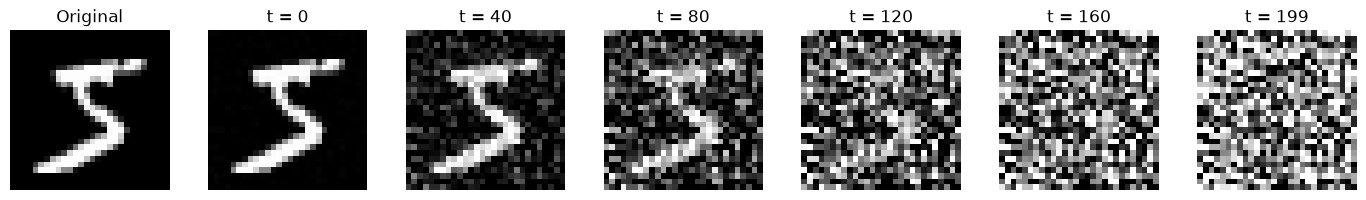

In [34]:
x0, _ = train_dataset[0]
x0 = x0.unsqueeze(0).to(device)

times = [0, 40, 80, 120, 160, 199]
noise = torch.randn_like(x0)

fig, axes = plt.subplots(1, len(times) + 1, figsize=(14, 2))

axes[0].imshow(
    x0[0, 0].cpu(),
    cmap="gray",
    vmin=-1,
    vmax=1
)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, step in zip(axes[1:], times):
    t = torch.tensor([step], device=device)
    xt, _ = add_noise(x0, t, noise)

    ax.imshow(
        xt[0, 0].cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    ax.set_title(f"t = {step}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [35]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2

        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(
                half,
                device=t.device,
                dtype=torch.float32
            )
            / (half - 1)
        )

        angles = t.float()[:, None] * frequencies[None, :]

        return torch.cat([
            angles.sin(),
            angles.cos()
        ], dim=1)


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_projection = nn.Linear(time_dim, out_channels)

        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

    def forward(self, x, time_embedding):
        h = self.conv1(x)

        # Une information temporelle par canal.
        time_features = self.time_projection(time_embedding)
        h = h + time_features[:, :, None, None]

        return self.conv2(h)


class SmallUNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            TimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.encoder1 = ConvBlock(1, 32, time_dim)
        self.encoder2 = ConvBlock(32, 64, time_dim)
        self.middle = ConvBlock(64, 128, time_dim)

        self.pool = nn.AvgPool2d(2)

        self.decoder2 = ConvBlock(128 + 64, 64, time_dim)
        self.decoder1 = ConvBlock(64 + 32, 32, time_dim)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x, t):
        time_embedding = self.time_embedding(t)

        h1 = self.encoder1(x, time_embedding)               # 28 × 28
        h2 = self.encoder2(self.pool(h1), time_embedding)   # 14 × 14
        h = self.middle(self.pool(h2), time_embedding)     # 7 × 7

        h = F.interpolate(
            h, size=h2.shape[-2:], mode="nearest"
        )
        h = self.decoder2(
            torch.cat([h, h2], dim=1),
            time_embedding
        )

        h = F.interpolate(
            h, size=h1.shape[-2:], mode="nearest"
        )
        h = self.decoder1(
            torch.cat([h, h1], dim=1),
            time_embedding
        )

        return self.output(h)


diffusion_model = SmallUNet().to(device)

In [36]:
optimizer = torch.optim.Adam(
    diffusion_model.parameters(),
    lr=2e-4
)


def train_diffusion(model, loader, optimizer, epochs=20):
    history = []

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        n_images = 0

        for x, _ in loader:
            x = x.to(device)
            batch_size = x.size(0)

            # Un niveau de bruit différent pour chaque image.
            t = torch.randint(
                0, T,
                (batch_size,),
                device=device
            )

            xt, true_noise = add_noise(x, t)
            predicted_noise = model(xt, t)

            loss = F.mse_loss(predicted_noise, true_noise)

            optimizer.zero_grad()
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * batch_size
            n_images += batch_size

        mean_loss = total_loss / n_images
        history.append(mean_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"MSE bruit = {mean_loss:.4f}"
        )

    return history


history = train_diffusion(
    diffusion_model,
    train_loader,
    optimizer,
    epochs=20
)

Epoch 1/20 | MSE bruit = 0.1148
Epoch 2/20 | MSE bruit = 0.0578
Epoch 3/20 | MSE bruit = 0.0530
Epoch 4/20 | MSE bruit = 0.0499
Epoch 5/20 | MSE bruit = 0.0483
Epoch 6/20 | MSE bruit = 0.0471
Epoch 7/20 | MSE bruit = 0.0464
Epoch 8/20 | MSE bruit = 0.0455
Epoch 9/20 | MSE bruit = 0.0445
Epoch 10/20 | MSE bruit = 0.0442
Epoch 11/20 | MSE bruit = 0.0435
Epoch 12/20 | MSE bruit = 0.0431
Epoch 13/20 | MSE bruit = 0.0428
Epoch 14/20 | MSE bruit = 0.0425
Epoch 15/20 | MSE bruit = 0.0422
Epoch 16/20 | MSE bruit = 0.0421
Epoch 17/20 | MSE bruit = 0.0415
Epoch 18/20 | MSE bruit = 0.0415
Epoch 19/20 | MSE bruit = 0.0416
Epoch 20/20 | MSE bruit = 0.0415


In [37]:
@torch.no_grad()
def generate_images(model, n_samples=20):
    model.eval()
    model_device = next(model.parameters()).device

    # Réutiliser exactement le calendrier de l'entraînement.
    b = betas.to(model_device)
    a = 1.0 - b
    abar = torch.cumprod(a, dim=0)

    abar_prev = torch.cat([
        torch.ones(1, device=model_device),
        abar[:-1]
    ])

    # Variance du processus inverse.
    posterior_var = (
        b * (1.0 - abar_prev) / (1.0 - abar)
    )

    # Coefficients de la moyenne conditionnelle q(x_{t-1} | x_t, x_0).
    coef_x0 = (
        b * torch.sqrt(abar_prev) / (1.0 - abar)
    )

    coef_xt = (
        torch.sqrt(a) * (1.0 - abar_prev) / (1.0 - abar)
    )

    x = torch.randn(
        n_samples, 1, 28, 28,
        device=model_device
    )

    for step in reversed(range(len(b))):
        t = torch.full(
            (n_samples,),
            step,
            device=model_device,
            dtype=torch.long
        )

        predicted_noise = model(x, t)

        # Estimation de l'image propre.
        x0_pred = (
            x - torch.sqrt(1.0 - abar[step]) * predicted_noise
        ) / torch.sqrt(abar[step])

        # Les images propres d'entraînement sont dans [-1, 1].
        x0_pred = x0_pred.clamp(-1.0, 1.0)

        # Moyenne de l'étape précédente.
        mean = (
            coef_x0[step] * x0_pred
            + coef_xt[step] * x
        )

        if step > 0:
            x = (
                mean
                + torch.sqrt(posterior_var[step])
                * torch.randn_like(x)
            )
        else:
            x = mean

        if not torch.isfinite(x).all():
            raise RuntimeError(
                f"Valeurs non finies pendant la génération, étape {step}"
            )

    return ((x + 1.0) / 2.0).clamp(0, 1).cpu()

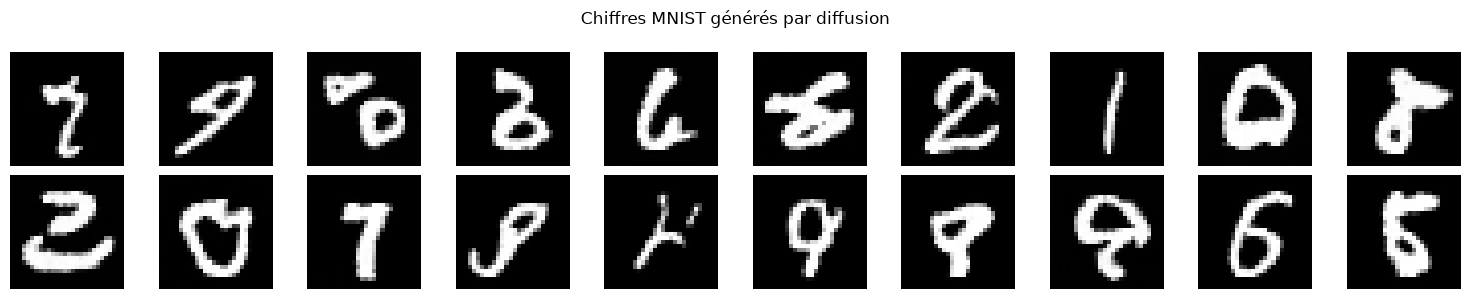

In [38]:
samples = generate_images(diffusion_model, n_samples=20)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        samples[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.suptitle("Chiffres MNIST générés par diffusion")
plt.tight_layout()
plt.show()

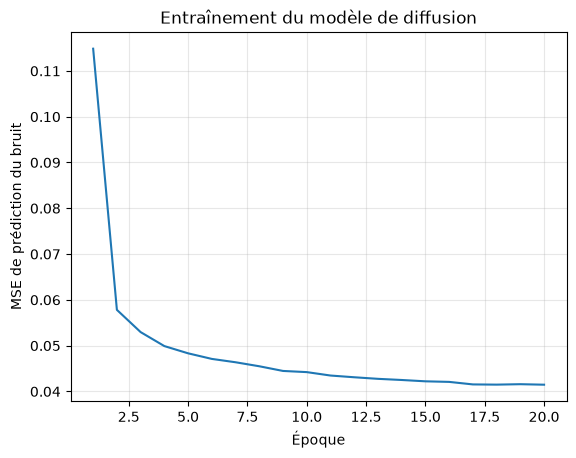

In [39]:
plt.plot(range(1, len(history) + 1), history)
plt.xlabel("Époque")
plt.ylabel("MSE de prédiction du bruit")
plt.title("Entraînement du modèle de diffusion")
plt.grid(alpha=0.3)
plt.show()